# 05. Étape 3 : premiers modèles, `fit` / `eval` / `predict`

**Projet AutoML, Challenge Machine Learning (M1 IA, Le Mans Université)**

Ce notebook lance le pipeline complet sur les 6 jeux et montre :

1. quels modèles ont été essayés, leur score de validation et leur durée ;
2. le score de **validation** (sert à choisir) comparé au score du **test interne** (jamais utilisé pour choisir) ;
3. que `predict` renvoie exactement la forme du fichier `.solution` ;
4. deux visualisations des erreurs : matrice de confusion (`data_D`) et prédiction contre vérité (`data_B`).

**Important : les modèles ne sont pas encore optimisés.** Ils tournent avec leurs réglages par défaut.
L'optimisation des hyperparamètres (Optuna) et l'ensemble de modèles restent à faire.
Explications détaillées : `docs/ETAPE3_PREMIERS_MODELES.md`.

In [1]:
import os, sys, time, io, contextlib, tempfile
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

# Importer le package automl/ du projet sans l'installer
sys.path.insert(0, os.path.abspath(".."))
DATA = os.path.abspath(os.path.join("..", "dataset"))
JEUX = ["data_A", "data_B", "data_C", "data_D", "data_E", "data_F"]
plt.rcParams["figure.dpi"] = 90
print("Données lues dans :", DATA)

Données lues dans : /Users/zakariafarach/Documents/UNIV/M1_IA/S1/CraftedAutoML/mon_projet/dataset


## Paramètres de l'expérience

Le budget réel sera fixé par l'évaluateur via `AUTOML_TIME_BUDGET`. Ici on choisit un budget de test
pour que le notebook s'exécute en quelques minutes ; modifiez-le pour voir l'effet sur les modèles essayés.

In [2]:
os.environ["AUTOML_TIME_BUDGET"] = "120"   # secondes par appel à fit (valeur de test)
os.environ["AUTOML_N_JOBS"] = "4"          # nombre de cœurs autorisés

import automl
from automl.data import load_solution

## 1. Entraînement sur les 6 jeux

In [3]:
resultats = {}
for nom in JEUX:
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):   # masque les messages de fit
        m = automl.AutoML().fit(os.path.join(DATA, nom))
    resultats[nom] = (m, time.time() - t0)
    print(f"{nom}: {m.task.task:18s} modèle retenu = {m.metrics['model']:24s} fit = {time.time() - t0:5.1f} s")

data_A: multilabel         modèle retenu = hist_gradient_boosting   fit =  17.7 s


data_B: regression         modèle retenu = hist_gradient_boosting   fit =   2.4 s


data_C: multiclass_onehot  modèle retenu = hist_gradient_boosting   fit =  90.4 s


data_D: binary             modèle retenu = random_forest            fit =   1.2 s


data_E: binary             modèle retenu = hist_gradient_boosting   fit =   2.5 s


data_F: multiclass_onehot  modèle retenu = linear_svc               fit =   8.1 s


## 2. Comparaison des modèles essayés

Les modèles sont essayés **du moins cher au plus cher**. Un modèle n'est lancé que si son temps estimé
(4 fois le plus lent déjà vu) tient dans le budget restant : un modèle absent du graphique a été sauté faute de temps.

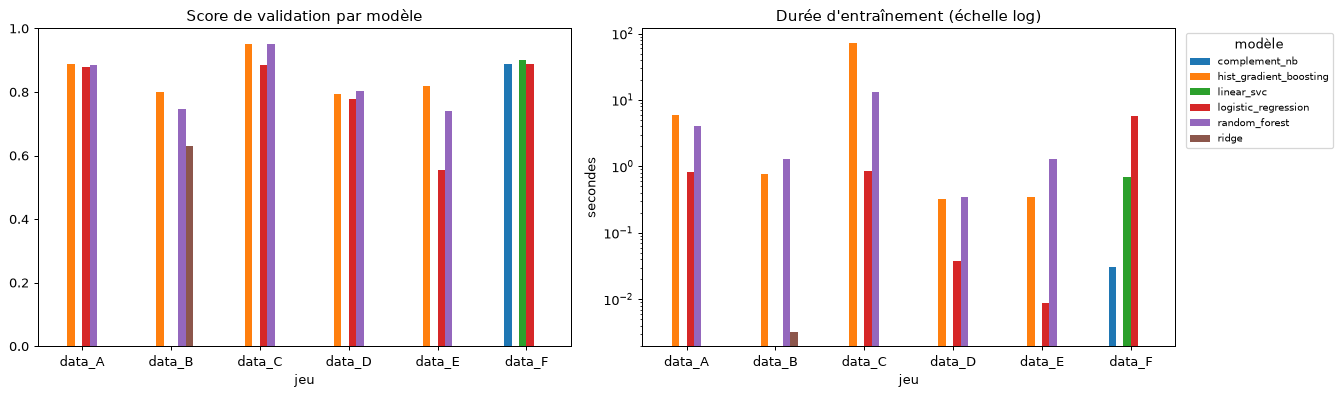

modèle,complement_nb,hist_gradient_boosting,linear_svc,logistic_regression,random_forest,ridge
jeu,,,,,,
data_A,NaN,0.8884,NaN,0.8795,0.8838,NaN
data_B,NaN,0.7991,NaN,NaN,0.7476,0.6305
data_C,NaN,0.9515,NaN,0.8852,0.9514,NaN
data_D,NaN,0.7935,NaN,0.7779,0.8040,NaN
data_E,NaN,0.8194,NaN,0.5562,0.7388,NaN
data_F,0.8893,NaN,0.8994,0.8886,NaN,NaN


In [4]:
lignes = []
for nom, (m, _) in resultats.items():
    for modele, score, duree in m.leaderboard:
        lignes.append({"jeu": nom, "modèle": modele, "score validation": score, "durée (s)": duree})
board = pd.DataFrame(lignes)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
board.pivot(index="jeu", columns="modèle", values="score validation").plot.bar(ax=axes[0], rot=0)
axes[0].set_title("Score de validation par modèle"); axes[0].set_ylim(0, 1)
axes[0].get_legend().remove()
board.pivot(index="jeu", columns="modèle", values="durée (s)").plot.bar(ax=axes[1], rot=0, logy=True)
axes[1].set_title("Durée d'entraînement (échelle log)"); axes[1].set_ylabel("secondes")
axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left", title="modèle")
plt.tight_layout(); plt.show()
board.pivot(index="jeu", columns="modèle", values="score validation").round(4)

## 3. Validation contre test interne

Le score de validation sert à **choisir** le modèle, il est donc un peu optimiste. Le test interne n'a servi
à aucun choix : c'est l'estimation honnête de ce qu'on obtiendra sur un jeu inconnu.
Si les deux barres sont proches, le choix du modèle n'a pas « sur-appris » la validation.

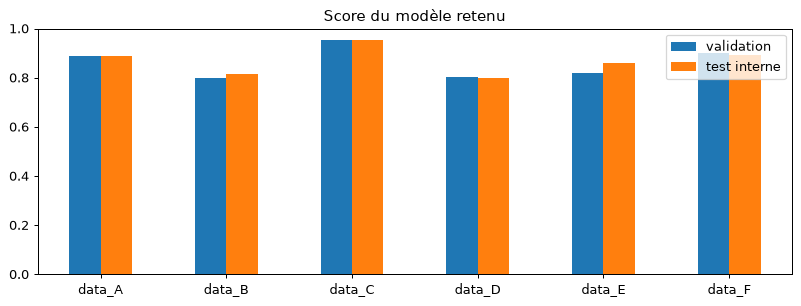

,validation,test interne,modèle
data_A,0.888356,0.888217,hist_gradient_boosting
data_B,0.799106,0.816161,hist_gradient_boosting
data_C,0.951527,0.953127,hist_gradient_boosting
data_D,0.803969,0.796789,random_forest
data_E,0.819429,0.859733,hist_gradient_boosting
data_F,0.899446,0.892443,linear_svc


In [5]:
tab = pd.DataFrame({nom: {"validation": m.metrics["valid_score"], "test interne": m.metrics["test_score"],
                          "modèle": m.metrics["model"]} for nom, (m, _) in resultats.items()}).T
tab[["validation", "test interne"]].astype(float).plot.bar(rot=0, figsize=(9, 3.5), ylim=(0, 1),
                                                            title="Score du modèle retenu")
plt.tight_layout(); plt.show()
tab

## 4. `predict` respecte le contrat du sujet

On prédit sur chaque dossier (qui contient aussi `.solution`, ici seulement pour comparer les formes).
Le sujet impose : même forme que `.solution`, et en multiclasse one-hot, une matrice one-hot.

In [6]:
lignes = []
for nom, (m, _) in resultats.items():
    with contextlib.redirect_stdout(io.StringIO()):
        preds = m.predict(os.path.join(DATA, nom))
    sol = load_solution(os.path.join(DATA, nom, nom + ".solution"))
    onehot_ok = bool(np.all(preds.sum(axis=1) == 1)) if m.task.task == "multiclass_onehot" else None
    lignes.append({"jeu": nom, "forme solution": sol.shape, "forme prédiction": preds.shape,
                   "même forme": preds.shape == sol.shape, "one-hot : lignes qui somment à 1": onehot_ok})
pd.DataFrame(lignes).set_index("jeu")

,forme solution,forme prédiction,même forme,one-hot : lignes qui somment à 1
jeu,,,,
data_A,"(34190, 3)","(34190, 3)",True,None
data_B,"(5000,)","(5000,)",True,None
data_C,"(15000, 10)","(15000, 10)",True,True
data_D,"(2984,)","(2984,)",True,None
data_E,"(3140,)","(3140,)",True,None
data_F,"(13142, 20)","(13142, 20)",True,True


## 5. Visualiser les erreurs sur le test interne

Le modèle final est réentraîné sur train + validation : le test interne n'a toujours jamais été vu.

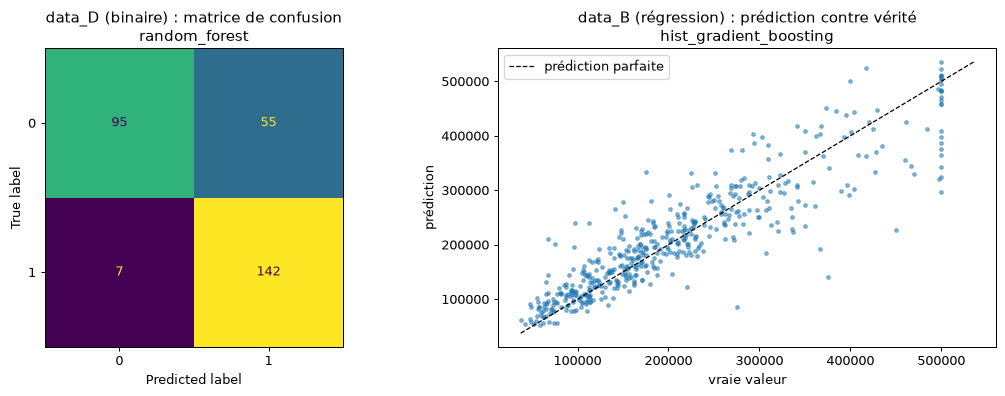

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

m, _ = resultats["data_D"]
X_te, y_te = m.splits["test"]
ConfusionMatrixDisplay.from_predictions(y_te, m.model.predict(X_te), ax=axes[0], colorbar=False)
axes[0].set_title(f"data_D (binaire) : matrice de confusion\n{m.metrics['model']}")

m, _ = resultats["data_B"]
X_te, y_te = m.splits["test"]
pred = m.model.predict(X_te)
axes[1].scatter(y_te, pred, s=8, alpha=0.5)
lim = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
axes[1].plot(lim, lim, "k--", linewidth=1, label="prédiction parfaite")
axes[1].set_xlabel("vraie valeur"); axes[1].set_ylabel("prédiction")
axes[1].set_title(f"data_B (régression) : prédiction contre vérité\n{m.metrics['model']}")
axes[1].legend()
plt.tight_layout(); plt.show()

## Ce qu'il faut retenir, et ce qu'il reste à faire

**Fait :** sur les 6 jeux, `fit` entraîne plusieurs modèles, garde le meilleur, respecte le budget temps,
et `predict` renvoie le format exact attendu.

**Pas encore fait (là où on peut gagner des points) :**

1. **Optimisation des hyperparamètres avec Optuna** : tous les modèles utilisent leurs réglages par défaut.
2. **Ensemble de modèles** : combiner les meilleurs modèles au lieu d'en garder un seul.
3. **Cible asymétrique** (`data_B`) : essayer un modèle sur `log(1 + y)`.
4. **Prétraitement dédié aux arbres** : aujourd'hui, tous les modèles reçoivent les mêmes données standardisées.